<a href="https://colab.research.google.com/github/25kaduta-design/GENAI/blob/main/Practical6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
torch.manual_seed(42)

# 1. Define the input tokens and basic dimensions
tokens = ["I", "love", "music"]
seq_len = len(tokens)

# Let's define embedding dimension (d_model) and projection dimensions (d_k, d_v)
d_model = 16
d_k = 8
d_v = 8

In [ ]:
# 2. Initialize toy embeddings for our tokens
# In a real model, these would come from an embedding layer or previous encoder layer
embeddings = torch.randn(seq_len, d_model)
print("Input Embeddings (Hidden States):")
for token, emb in zip(tokens, embeddings):
    print(f"{token}: {emb[:4].tolist()}... (dimension: {d_model})")

Input Embeddings (Hidden States):
I: [1.9269152879714966, 1.4872840642929077, 0.9007171988487244, -2.1055209636688232]... (dimension: 16)
love: [1.6423169374465942, -0.1595974713563919, -0.4973975419998169, 0.439589262008667]... (dimension: 16)
music: [-1.3846737146377563, -0.8712361454963684, -0.223365917801857, 1.7173614501953125]... (dimension: 16)


In [ ]:
# 3. Define Query (Q), Key (K), and Value (V) projection matrices
W_q = torch.randn(d_model, d_k)
W_k = torch.randn(d_model, d_k)
W_v = torch.randn(d_model, d_v)

Q = torch.matmul(embeddings, W_q)
K = torch.matmul(embeddings, W_k)
V = torch.matmul(embeddings, W_v)

print("\nQuery (Q) Shape:", Q.shape)
print("Key (K) Shape:", K.shape)
print("Value (V) Shape:", V.shape)


Query (Q) Shape: torch.Size([3, 8])
Key (K) Shape: torch.Size([3, 8])
Value (V) Shape: torch.Size([3, 8])


In [ ]:
# 4. Raw Attention Scores (Q * K^T)
attn_scores = torch.matmul(Q, K.transpose(0, 1))

# 5. Attention Distribution (Softmax)
attn_distribution = F.softmax(attn_scores, dim=-1)

print("Attention Scores:\n", attn_scores.numpy())
print("\nAttention Distribution (Softmax weights):\n", attn_distribution.numpy())

Attention Scores:
 [[-10.705313 -11.606056  62.89357 ]
 [-84.69232   26.995045   6.62294 ]
 [ 69.42341    5.606927 -28.202374]]

Attention Distribution (Softmax weights):
 [[1.0874531e-32 4.4179772e-33 1.0000000e+00]
 [0.0000000e+00 1.0000000e+00 1.4207163e-09]
 [1.0000000e+00 1.9268761e-28 3.9937006e-43]]


In [ ]:
# 6. Calculate Final Attention Output Vectors
attention_output = torch.matmul(attn_distribution, V)

print("Output Attention Vectors Shape:", attention_output.shape)
for token, val in zip(tokens, attention_output):
    print(f"{token} attention vector: {val.tolist()}")

Output Attention Vectors Shape: torch.Size([3, 8])
I attention vector: [-0.28153765201568604, 2.5002551078796387, -4.627270221710205, -0.3331648111343384, -2.7299487590789795, 0.5726194381713867, 1.9096590280532837, 3.625087022781372]
love attention vector: [1.205305814743042, -0.20463502407073975, 0.6646873950958252, 2.9705708026885986, 0.8537550568580627, 0.4841350317001343, -8.405143737792969, 4.908855438232422]
music attention vector: [-2.911343574523926, -7.731362819671631, 4.0331196784973145, -6.461052894592285, -1.3542560338974, 5.622637748718262, -0.03210878372192383, -7.555790901184082]


Text(45.722222222222214, 0.5, 'Queries (Target Tokens)')

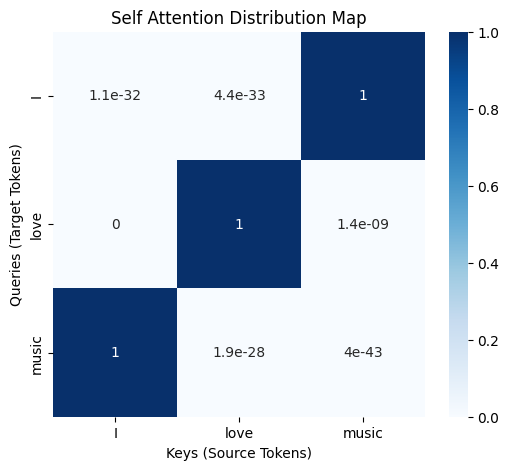

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    attn_distribution.detach().numpy(),
    annot=True,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="Blues",
    cbar=True,
    vmin=0,
    vmax=1
)

plt.title("Self Attention Distribution Map")
plt.xlabel("Keys (Source Tokens)")
plt.ylabel("Queries (Target Tokens)")

In [ ]:
# Explicitly show the math for step by step computation

for i, q_token in enumerate(tokens):
  print(f"\n--- Calculation for Query token: '{q_token.strip()}' ----")
  q_vec = Q[i]

  raw_scores = []
  scaled_scores = []

  for j, k_token in enumerate(tokens):
    k_vec = K[j]
    dot_prod = torch.dot(q_vec, k_vec).item()
    # Standard scaling factor for transformer attention is sqrt(d_k)
    scaled_prod = dot_prod / np.sqrt(d_k)

    raw_scores.append(dot_prod)
    scaled_scores.append(scaled_prod)

    print(f"  Key '{k_token.strip()}': Raw Score = {dot_prod:.4f}, Scaled Score = {scaled_prod:.4f}")

  # Compute manual Softmax
  exp_scores = np.exp(scaled_scores)
  sum_exp = np.sum(exp_scores)
  probabilities = exp_scores / sum_exp

  print(f"  Softmax Distribution:")
  for j, k_token in enumerate(tokens):
    print(f"    to '{k_token.strip()}': {probabilities[j]:.4f}")


--- Calculation for Query token: 'I' ----
  Key 'I': Raw Score = -10.7053, Scaled Score = -3.7849
  Key 'love': Raw Score = -11.6061, Scaled Score = -4.1034
  Key 'music': Raw Score = 62.8936, Scaled Score = 22.2362
  Softmax Distribution:
    to 'I': 0.0000
    to 'love': 0.0000
    to 'music': 1.0000

--- Calculation for Query token: 'love' ----
  Key 'I': Raw Score = -84.6923, Scaled Score = -29.9433
  Key 'love': Raw Score = 26.9950, Scaled Score = 9.5442
  Key 'music': Raw Score = 6.6229, Scaled Score = 2.3416
  Softmax Distribution:
    to 'I': 0.0000
    to 'love': 0.9993
    to 'music': 0.0007

--- Calculation for Query token: 'music' ----
  Key 'I': Raw Score = 69.4234, Scaled Score = 24.5449
  Key 'love': Raw Score = 5.6069, Scaled Score = 1.9823
  Key 'music': Raw Score = -28.2024, Scaled Score = -9.9710
  Softmax Distribution:
    to 'I': 1.0000
    to 'love': 0.0000
    to 'music': 0.0000


In [ ]:
num_heads = 2

d_k_head = d_model // num_heads
d_v_head = d_model // num_heads

print(f"Embedding dimension (d_model): {d_model}")
print(f"Head dimension (d_k): {d_k_head}")
print(f"Head dimension (d_v): {d_v_head}")

Embedding dimension (d_model): 16
Head dimension (d_k): 8
Head dimension (d_v): 8


In [ ]:
# Initialize MHA weights
W_q_mha = torch.randn(d_model, d_model)  # Projecting to all heads combined
W_k_mha = torch.randn(d_model, d_model)
W_v_mha = torch.randn(d_model, d_model)
W_o = torch.randn(d_model, d_model)      # Final output projection weight

# Step 1: Linear projections
Q_mha = torch.matmul(embeddings, W_q_mha)
K_mha = torch.matmul(embeddings, W_k_mha)
V_mha = torch.matmul(embeddings, W_v_mha)

# Step 2: Reshape to split into heads
# New shape: [seq_len, num_heads, d_k_head]
Q_split = Q_mha.view(seq_len, num_heads, d_k_head).transpose(0, 1)
K_split = K_mha.view(seq_len, num_heads, d_k_head).transpose(0, 1)
V_split = V_mha.view(seq_len, num_heads, d_v_head).transpose(0, 1)

print("Split Queries Shape (num_heads, seq_len, d_k_head):", Q_split.shape)
print("Split Keys Shape (num_heads, seq_len, d_k_head):", K_split.shape)
print("Split Values Shape (num_heads, seq_len, d_v_head):", V_split.shape)
# Step 3: Compute attention scores and distribution for each head independently

scores = torch.matmul(Q_split, K_split.transpose(-2, -1)) / (d_k_head ** 0.5)
distributions = F.softmax(scores, dim=-1)
head_outputs = torch.matmul(distributions, V_split)

# Step 4: Concatenate head outputs
# Transpose back to [seq_len, num_heads, d_v_head] and flatten the last two dimensions
concat_output = head_outputs.transpose(0, 1).contiguous().view(seq_len, d_model)

# Step 5: Final output projection
final_output = torch.matmul(concat_output, W_o)

print("Attention Distribution Shape (for all heads):", distributions.shape)
print("Concatenated Output Shape:", concat_output.shape)
print("Final Multi-head Attention Output Shape:", final_output.shape)


Split Queries Shape (num_heads, seq_len, d_k_head): torch.Size([2, 3, 8])
Split Keys Shape (num_heads, seq_len, d_k_head): torch.Size([2, 3, 8])
Split Values Shape (num_heads, seq_len, d_v_head): torch.Size([2, 3, 8])
Attention Distribution Shape (for all heads): torch.Size([2, 3, 3])
Concatenated Output Shape: torch.Size([3, 16])
Final Multi-head Attention Output Shape: torch.Size([3, 16])


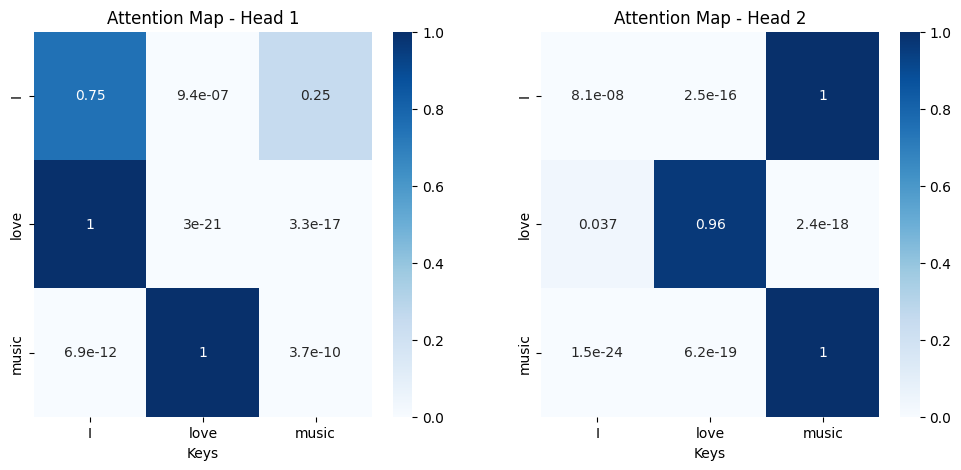

In [ ]:
# Let's visualize the attention maps for both heads side-by-side
fig, axes = plt.subplots(1, num_heads, figsize=(12, 5))

for h in range(num_heads):
    sns.heatmap(
        distributions[h].detach().numpy(),
        annot=True,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="Blues",
        cbar=True,
        vmin=0,
        vmax=1,
        ax=axes[h]
    )
    axes[h].set_title(f"Attention Map - Head {h+1}")
    axes[h].set_xlabel("Keys")